In [1]:
from simulation.halo_sim import RocketSim
from controls.halo_controls import Controls
from runner.halo_runner import Runner
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import direct, Bounds
from parameters import halojr_params, halo_params

## Halo parameter flight sim

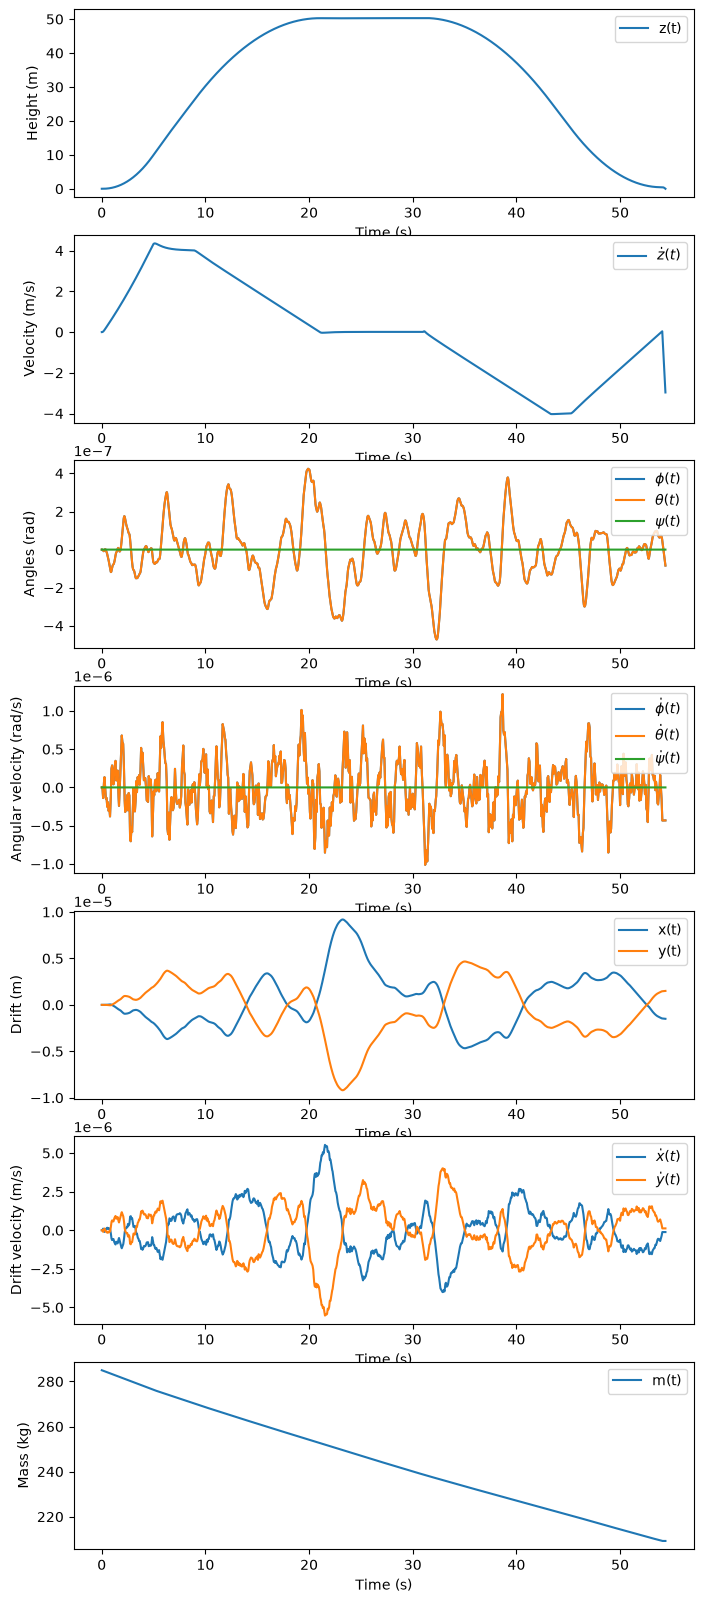

In [2]:
halo_sim = RocketSim(halo_params)
halo_controls = Controls(halo_params)
halo_runner = Runner(halo_controls, halo_sim) 

halo_runner.clear_cache()
halo_runner.solve(halo_params["State0"])
halo_runner.plot_cache(interval=(0,65))

## Halo Jr parameter flight sim

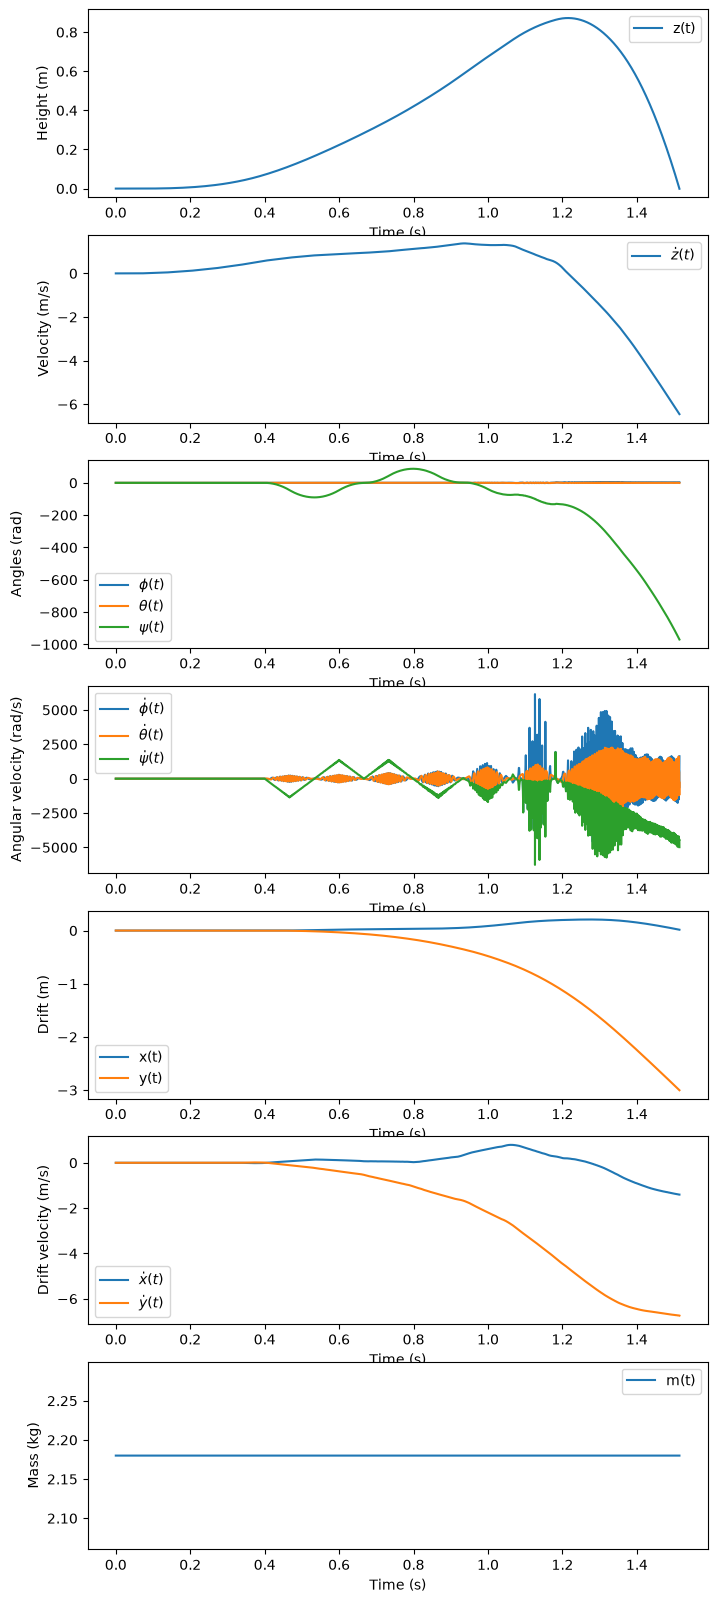

In [5]:
halojr_sim = RocketSim(halojr_params)
halojr_controls = Controls(halojr_params)
halojr_runner = Runner(halojr_controls, halojr_sim) 

halojr_runner.clear_cache()
halojr_runner.solve(halojr_params["State0"])
halojr_runner.plot_cache(interval=(0,65))

## Optimizing LQR parameters
Cost is the integral of the square of the difference between the true height and desired height: $\text{Cost} = \int_{0}^{t_f} \left( z(t)-z_{ref}(t) \right)^2 dt$

DIRECT optimization is used to find the global minimum within the bounds over the Q and R matrix diagonals

In [ ]:
def Cost(Qx,Qz,Qdx,Qdz,Qtheta,Qdtheta,Rgamma,RP,params):
    params = dict(params) 
    params["Q"] = np.diag([Qx, Qz, Qdx, Qdz, Qtheta, Qdtheta])
    params["R"] = np.diag([Rgamma, RP])
    sim = RocketSim(params)
    controls = Controls(params)
    runner = Runner(controls, sim)
    runner.solve(params["State0"])

    timestamps = runner.timestamps_cache[-1]
    height = runner.states_cache[-1][2]
    ref = [controls.z_ref(t) for t in timestamps]
    status = runner.status_cache[-1]

    if status == 0:
        Cost = np.sum([((height-ref) ** 2)[i] * (timestamps[i+1]-timestamps[i]) for i in range(len(timestamps)-1)])
    elif status == 2 and params["t_final"]-timestamps[-1]<1:
        Cost = np.sum([((height-ref) ** 2)[i] * (timestamps[i+1]-timestamps[i]) for i in range(len(timestamps)-1)])
    else:
        Cost = 1e10

    return Cost

# bounds define the min and max for each
bounds = Bounds(
    [0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01], # minimums
    [10, 5000, 10, 100000, 1000, 500, 1500, 30000] # maximums
)

# the lambda takes as input x, and outputs Cost(*x, params = halo_params)
# direct optimizes the value of x and stays within the bounds defined
result = direct(lambda x: Cost(*x, params=halojr_params), bounds)

best_x = result.x
min_cost = result.fun      
print(best_x, min_cost, result.nfev)

## Optimizing trajectory shape

VFinal is the final speed of the rocket at touchdown. This is minimized over the parameter Z, which shapes the trajectory to ascend and descend more or less gradually

In [ ]:
def VFinal(x, params):
    params = dict(params)
    Z = float(x[0])
    params["Z"] = Z
    sim = RocketSim(params)
    controls = Controls(params)
    runner = Runner(controls, sim)
    runner.solve(params["State0"])

    vfinal = runner.states_cache[-1][5][-1]
    timestamps = runner.timestamps_cache[-1]
    status = runner.status_cache[-1]
    if status == 2 and params["t_final"]-timestamps[-1]<.5:
        return np.abs(vfinal)
    else:
        return 1e10

bounds = Bounds([0.01], [7.6]) 
result = direct(lambda x : VFinal(x,params = halojr_params), bounds)

best_x = result.x
min_cost = result.fun  
print(best_x, min_cost, result.nfev)

## Visualization of cost landscape

In [ ]:
Qz_array = np.linspace(1,100,20)
Qdz_array = np.linspace(500, 4000, 30)
Parameter_array = np.empty((len(Qz_array),len(Qdz_array),2))
for i in range(len(Qz_array)):
    for j in range(len(Qdz_array)):
        Parameter_array[i][j] = (Qz_array[i],Qdz_array[j])
Cost_array = np.empty(Parameter_array.shape[:2])
for i in range(Parameter_array.shape[0]):
    for j in range(Parameter_array.shape[1]):
        (Qz,Qdz) = Parameter_array[i][j]
        Cost_array[i,j] = Cost(4,Qz,4,Qdz,131,8.2,200,1500,halojr_params)

X, Y = np.meshgrid(Qz_array, Qdz_array, indexing="ij")   # same shape as Cost_array

fig = plt.figure()
ax = fig.add_subplot(projection="3d")
surf = ax.plot_surface(X, Y, -Cost_array, cmap="viridis")

ax.set_xlabel("Qz")
ax.set_ylabel("Qdz")
ax.set_zlabel("Neg Cost")
fig.colorbar(surf, shrink=0.6, label="Neg Cost")
plt.show()

In [ ]:
X, Y = np.meshgrid(Qz_array, Qdz_array[:25], indexing="ij")   # same shape as Cost_array
Trunc = Cost_array[:, :25]

fig = plt.figure()
ax = fig.add_subplot(projection="3d")
surf = ax.plot_surface(X, Y, -Trunc, cmap="viridis")

ax.set_xlabel("Qz")
ax.set_ylabel("Qdz")
ax.set_zlabel("Neg Cost")
fig.colorbar(surf, shrink=0.6, label="Neg Cost")
plt.show()